# Email Spam Detection with Machine Learning
**Oasis Infobyte Data Science Internship — Task 4**

## Objective
Classify messages as spam or legitimate (ham) using text features and two machine-learning classifiers.

## Dataset
The UCI SMS Spam Collection is a small public dataset commonly used for spam classification. It contains labelled messages. This notebook downloads the ZIP file directly; if your environment blocks the download, download the dataset from the UCI Machine Learning Repository and upload `SMSSpamCollection` to Colab.

In [1]:
import io
import zipfile
import urllib.request

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")

## 1. Load and inspect the dataset

In [2]:
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
with urllib.request.urlopen(url, timeout=30) as response:
    archive_bytes = response.read()

with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
    with archive.open("SMSSpamCollection") as file:
        df = pd.read_csv(file, sep="\\t", header=None, names=["label", "message"], encoding="utf-8")

print("Dataset shape:", df.shape)
display(df.head())
print("\\nMissing values:")
print(df.isnull().sum())
print("\\nClass counts:")
display(df["label"].value_counts().to_frame("count"))
display((df["label"].value_counts(normalize=True) * 100).round(2).to_frame("percent"))

Dataset shape: (5574, 2)


/tmp/ipykernel_1021/3473829964.py:7: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(file, sep="\\t", header=None, names=["label", "message"], encoding="utf-8")


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


\nMissing values:
label      0
message    0
dtype: int64
\nClass counts:


,count
label,
ham,4827
spam,747


,percent
label,
ham,86.6
spam,13.4


## 2. Class distribution and text preparation

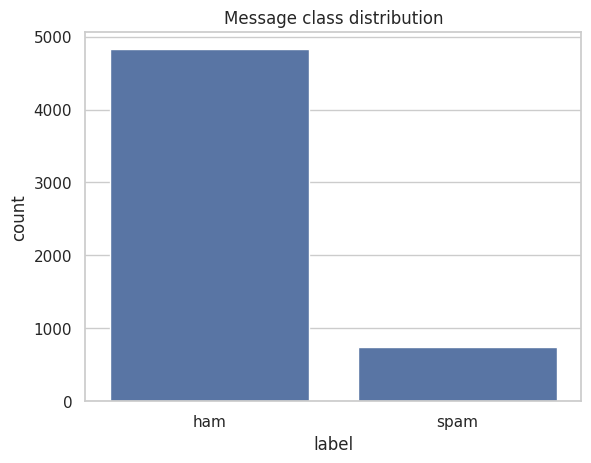

Training messages: 4459
Test messages: 1115


In [3]:
sns.countplot(data=df, x="label")
plt.title("Message class distribution")
plt.show()

# TF-IDF converts text into numeric features. Words that are common in one message
# but less common across all messages receive higher weight than very common words.
X = df["message"].astype(str)
y = df["label"].map({"ham": 0, "spam": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training messages:", len(X_train))
print("Test messages:", len(X_test))

## 3. Train two classifiers and evaluate

\nMultinomial Naive Bayes accuracy: 0.966
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.74      0.85       149

    accuracy                           0.97      1115
   macro avg       0.98      0.87      0.92      1115
weighted avg       0.97      0.97      0.96      1115



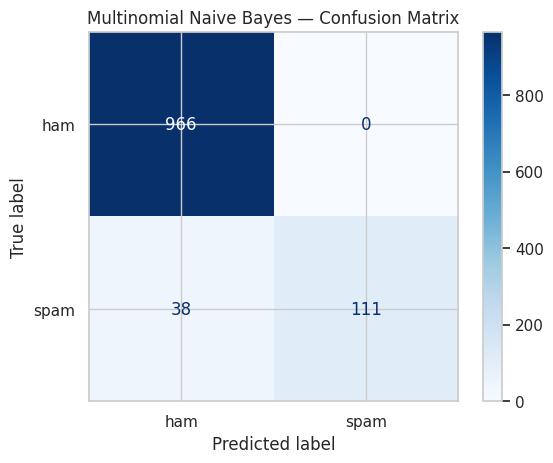

\nLogistic Regression accuracy: 0.979
              precision    recall  f1-score   support

         ham       0.99      0.98      0.99       966
        spam       0.90      0.95      0.93       149

    accuracy                           0.98      1115
   macro avg       0.95      0.97      0.96      1115
weighted avg       0.98      0.98      0.98      1115



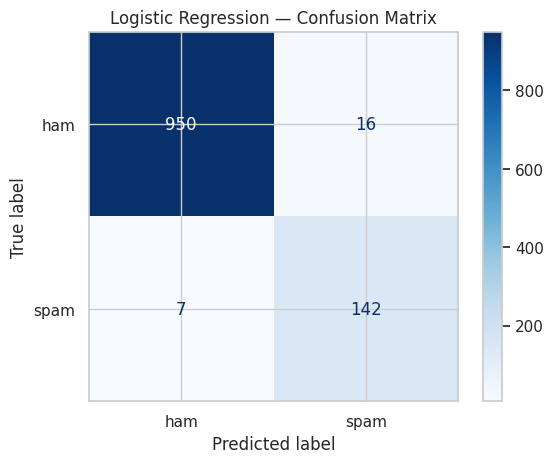

Best model by accuracy on this test split: Logistic Regression


In [4]:
models = {
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2))),
        ("classifier", MultinomialNB())
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2))),
        ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
    ])
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results[name] = {
        "model": model,
        "predictions": pred,
        "accuracy": accuracy_score(y_test, pred)
    }
    print(f"\\n{name} accuracy: {results[name]['accuracy']:.3f}")
    print(classification_report(y_test, pred, target_names=["ham", "spam"], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["ham", "spam"], cmap="Blues"
    )
    plt.title(f"{name} — Confusion Matrix")
    plt.show()

best_name = max(results, key=lambda name: results[name]["accuracy"])
print(f"Best model by accuracy on this test split: {best_name}")

## 4. Why recall matters for spam detection
Spam recall measures the fraction of actual spam messages that the model correctly identifies. Low spam recall means more spam slips into the legitimate inbox. However, precision also matters because low precision can incorrectly send legitimate messages to spam.

## 5. Conclusion
The Email Spam Detection project successfully applied machine learning techniques to classify text messages as spam or ham (legitimate messages). The text data was processed and converted into numerical features so that a Logistic Regression model could learn patterns associated with spam messages.

The Logistic Regression model achieved 97.9% accuracy on the test dataset. It correctly classified 950 legitimate messages and 142 spam messages, while misclassifying 16 legitimate messages as spam and 7 spam messages as legitimate.

The spam recall was approximately 95%, meaning the model identified most of the actual spam messages. Overall, the project demonstrates how machine learning and natural language processing can help automate spam detection. Further improvements could include testing other classification algorithms and evaluating the model on a wider variety of messages.
